In [2]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV      #Validación cruzada y optimización de parámetros
from sklearn.ensemble import RandomForestClassifier                                     #Random forest clasificación
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
import time
import warnings
warnings.filterwarnings('ignore')

Carga de datos de entrenamiento y prueba

In [3]:
#Se cargan los datos escalados y preparados del avance 1, mantienen la proporción de la data original de 80-20 para churn

X_train_scaled = pd.read_csv('../data/processed/X_train_final_escalado.csv', index_col=0, encoding='utf-8')
X_test_scaled = pd.read_csv('../data/processed/X_test_final_escalado.csv', index_col=0, encoding='utf-8')

#Se vuelven a convertir en una serie con .squeeze()
y_train = pd.read_csv('../data/processed/y_train_final.csv', index_col=0, encoding='utf-8').squeeze('columns')
y_test = pd.read_csv('../data/processed/y_test_final.csv', index_col=0, encoding='utf-8').squeeze('columns')


print(f'Conjunto de Entrenamiento: X {X_train_scaled.shape} | y {y_train.shape}')
print(f'Conjunto de Prueba:        X {X_test_scaled.shape}  | y {y_test.shape}')
print(f'Proporción de Churn en Train: {y_train.mean():.4f}')
print(f'Proporción de Churn en Test:  {y_test.mean():.4f}')

Conjunto de Entrenamiento: X (8000, 11) | y (8000,)
Conjunto de Prueba:        X (2000, 11)  | y (2000,)
Proporción de Churn en Train: 0.2037
Proporción de Churn en Test:  0.2035


Entrenamiento de modelos

In [4]:
# Random Forest
#Entrenamiento en paralelo
#Para datos desbalanceados class_weight='balanced'
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)

#Solo para determinar si hay underfitting u overfitting como base de comparación
y_train_pred_rf = rf_model.predict(X_train_scaled)
y_train_prob_rf = rf_model.predict_proba(X_train_scaled)[:, 1]

#Test
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

print("=== MÉTRICAS De EVALUACIÓN ===")
print(f"Accuracy [Train]:  {accuracy_score(y_train, y_train_pred_rf):.4f} | [Test]: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision [Train]: {precision_score(y_train, y_train_pred_rf, pos_label=1):.4f} | [Test]: {precision_score(y_test, y_pred_rf, pos_label=1):.4f}")
print(f"Recall    [Train]: {recall_score(y_train, y_train_pred_rf, pos_label=1):.4f} | [Test]: {recall_score(y_test, y_pred_rf, pos_label=1):.4f}")
print(f"F1-Score [Train]:  {f1_score(y_train, y_train_pred_rf):.4f} | [Test]: {f1_score(y_test, y_pred_rf, pos_label=1):.4f}")
print("-" * 50)


print("=== MÉTRICAS PARA DIAGNÓSTICO DE UNDERFITTING/OVERFITTING ===")
print(f"ROC-AUC  [Train]: {roc_auc_score(y_train, y_train_prob_rf):.4f} | [Test]: {roc_auc_score(y_test, y_pred_prob_rf):.4f}")
print(f"PR-AUC   [Train]: {average_precision_score(y_train, y_train_prob_rf):.4f} | [Test]: {average_precision_score(y_test, y_pred_prob_rf):.4f}")

=== MÉTRICAS De EVALUACIÓN ===
Accuracy [Train]:  0.7971 | [Test]: 0.7930
Precision [Train]: 0.5014 | [Test]: 0.4944
Recall    [Train]: 0.7503 | [Test]: 0.7568
F1-Score [Train]:  0.6011 | [Test]: 0.5981
--------------------------------------------------
=== MÉTRICAS PARA DIAGNÓSTICO DE UNDERFITTING/OVERFITTING ===
ROC-AUC  [Train]: 0.8647 | [Test]: 0.8561
PR-AUC   [Train]: 0.6957 | [Test]: 0.6819


Se realizó una prueba inicial con una profundidad de árboles de 10 (rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)) donde el ROC AUC en train era de 0.96 y en test de 0.86, una diferencia del 10% y en el recall una de 16% (Train:0.87|Test:0.71), indicando overfitting. Se redujo la profundidad del árbol a max_depth=5 y se logró una diferencia menor al 1% evitando el overfitting

Gradient Boosting

XGBoost

In [5]:
#Entrenamiento secuencial
#optimización de hiperparámetros solamente al modelo XGBoost,  utilizando Grid Search.
param_grid_xgb = {
    'n_estimators': [100, 200, 300],            #Número de árboles altos para bajos learning_rates
    'max_depth': [3, 5, 7],                     #Árboles medio y profundos
    'learning_rate': [0.01, 0.05, 0.1],         #Paso de aprendizaje
    'subsample': [0.8, 1.0],                    #Porcentaje de clinetes a evaluar
    'colsample_bytree': [0.5,0.8, 1.0],         #Porcentaje de columnas por árbol
    'reg_alpha': [0, 0.1],                      #L1 regularizacion Lasso
    'reg_lambda': [1, 10]                       #L2 regularizacion Ridge
}

#Total de combinaciones
n_combinations = 1
for values in param_grid_xgb.values():
    n_combinations *= len(values)
    
print(f' Total de combinaciones: {n_combinations}')
print(f' Con 5-fold CV: {n_combinations * 5} entrenamientos')
print(f' Esto puede tomar varios minutos...')


xgb_model_grid = GridSearchCV(xgb.XGBClassifier(random_state= 42, scale_pos_weight=3.91, eval_metric='logloss'),
                param_grid=param_grid_xgb,
                cv= StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                scoring='roc_auc',
                n_jobs=-1,
                verbose=2 )

start = time.time()
xgb_model_grid.fit(X_train_scaled, y_train)
print(f'Tiempo: {(time.time()-start)/60:.2f} min')

xgb_best = xgb_model_grid.best_estimator_
y_pred_xgb = xgb_best.predict(X_test_scaled)
y_pred_prob_xgb = xgb_best.predict_proba(X_test_scaled)[:,1]

print(f'Mejores parámetros: {xgb_model_grid.best_params_}')
print(f'Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f} | F1: {f1_score(y_test, y_pred_xgb):.4f}| ROC AUC: {roc_auc_score(y_test, y_pred_prob_xgb):.4f}')
print(f'CV Score: {xgb_model_grid.best_score_:.4f}')


 Total de combinaciones: 648
 Con 5-fold CV: 3240 entrenamientos
 Esto puede tomar varios minutos...
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Tiempo: 4.40 min
Mejores parámetros: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 1, 'subsample': 0.8}
Accuracy: 0.8060 | F1: 0.6135| ROC AUC: 0.8692
CV Score: 0.8658


El modelo XGBOOST se puede considerar un modelo robusto, ya que al comparar el promedio CV score con el ROC-AUC obtenido tienen una diferencia de 0.34%, esto también respalda que no haya overfitting

LightGBM

In [6]:
#  LightGBM
lgbm = lgb.LGBMClassifier(n_estimators=300, num_leaves=5, max_depth=5, learning_rate=0.05 , scale_pos_weight=3.91, random_state=42, verbose=-1)

start = time.time()
lgbm.fit(X_train_scaled, y_train)
train_time = time.time()-start

y_pred_lgbm = lgbm.predict(X_test_scaled)
y_pred_prob_lgbm = lgbm.predict_proba(X_test_scaled)[:, 1]

#Solo para determinar si hay underfitting u overfitting como base de comparación
y_train_pred_lgbm = lgbm.predict(X_train_scaled)
y_train_prob_lgbm = lgbm.predict_proba(X_train_scaled)[:, 1]

print(f'Tiempo: {train_time:.2f} s')

print("=== MÉTRICAS De EVALUACIÓN ===")
print(f"Accuracy [Train]:  {accuracy_score(y_train, y_train_pred_lgbm):.4f} | [Test]: {accuracy_score(y_test, y_pred_lgbm):.4f}")
print(f"Precision [Train]: {precision_score(y_train, y_train_pred_lgbm, pos_label=1):.4f} | [Test]: {precision_score(y_test, y_pred_lgbm, pos_label=1):.4f}")
print(f"Recall    [Train]: {recall_score(y_train, y_train_pred_lgbm, pos_label=1):.4f} | [Test]: {recall_score(y_test, y_pred_lgbm, pos_label=1):.4f}")
print(f"F1-Score [Train]:  {f1_score(y_train, y_train_pred_lgbm, pos_label=1):.4f} | [Test]: {f1_score(y_test, y_pred_lgbm, pos_label=1):.4f}")
print("-" * 50)


print("=== MÉTRICAS PARA DIAGNÓSTICO DE UNDERFITTING/OVERFITTING ===")
print(f"ROC-AUC  [Train]: {roc_auc_score(y_train, y_train_prob_lgbm):.4f} | [Test]: {roc_auc_score(y_test, y_pred_prob_lgbm):.4f}")
print(f"PR-AUC   [Train]: {average_precision_score(y_train, y_train_prob_lgbm):.4f} | [Test]: {average_precision_score(y_test, y_pred_prob_lgbm):.4f}")

Tiempo: 3.53 s
=== MÉTRICAS De EVALUACIÓN ===
Accuracy [Train]:  0.8130 | [Test]: 0.7965
Precision [Train]: 0.5277 | [Test]: 0.5000
Recall    [Train]: 0.7828 | [Test]: 0.7690
F1-Score [Train]:  0.6304 | [Test]: 0.6060
--------------------------------------------------
=== MÉTRICAS PARA DIAGNÓSTICO DE UNDERFITTING/OVERFITTING ===
ROC-AUC  [Train]: 0.8899 | [Test]: 0.8729
PR-AUC   [Train]: 0.7435 | [Test]: 0.7220


Catboost

In [7]:
cat = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.05, auto_class_weights='Balanced', random_state=42, verbose=False)
start = time.time()
cat.fit(X_train_scaled, y_train)
train_time= time.time() - start

y_pred_cat = cat.predict(X_test_scaled)
y_pred_prob_cat = cat.predict_proba(X_test_scaled)[:, 1]

#Solo para determinar si hay underfitting u overfitting como base de comparación
y_train_pred_cat = cat.predict(X_train_scaled)
y_train_prob_cat = cat.predict_proba(X_train_scaled)[:, 1]


print(f'Tiempo: {train_time:.2f} s')

print("=== MÉTRICAS De EVALUACIÓN ===")
print(f"Accuracy [Train]:  {accuracy_score(y_train, y_train_pred_cat):.4f} | [Test]: {accuracy_score(y_test, y_pred_cat):.4f}")
print(f"Precision [Train]: {precision_score(y_train, y_train_pred_cat, pos_label=1):.4f} | [Test]: {precision_score(y_test, y_pred_cat, pos_label=1):.4f}")
print(f"Recall    [Train]: {recall_score(y_train, y_train_pred_cat, pos_label=1):.4f} | [Test]: {recall_score(y_test, y_pred_cat, pos_label=1):.4f}")
print(f"F1-Score [Train]:  {f1_score(y_train, y_train_pred_cat, pos_label=1):.4f} | [Test]: {f1_score(y_test, y_pred_cat, pos_label=1):.4f}")
print("-" * 50)


print("=== MÉTRICAS PARA DIAGNÓSTICO DE UNDERFITTING/OVERFITTING ===")
print(f"ROC-AUC  [Train]: {roc_auc_score(y_train, y_train_prob_cat):.4f} | [Test]: {roc_auc_score(y_test, y_pred_prob_cat):.4f}")
print(f"PR-AUC   [Train]: {average_precision_score(y_train, y_train_prob_cat):.4f} | [Test]: {average_precision_score(y_test, y_pred_prob_cat):.4f}")

Tiempo: 1.46 s
=== MÉTRICAS De EVALUACIÓN ===
Accuracy [Train]:  0.8396 | [Test]: 0.8085
Precision [Train]: 0.5746 | [Test]: 0.5203
Recall    [Train]: 0.8196 | [Test]: 0.7568
F1-Score [Train]:  0.6756 | [Test]: 0.6166
--------------------------------------------------
=== MÉTRICAS PARA DIAGNÓSTICO DE UNDERFITTING/OVERFITTING ===
ROC-AUC  [Train]: 0.9142 | [Test]: 0.8714
PR-AUC   [Train]: 0.7837 | [Test]: 0.7258


Stacking

In [8]:
base_estimators = [
    ('xgb', xgb.XGBClassifier(**xgb_model_grid.best_params_,random_state= 42, scale_pos_weight=3.91, eval_metric='logloss')),
    ('lgbm', lgb.LGBMClassifier(n_estimators=300, num_leaves=5, max_depth=5, learning_rate=0.05, scale_pos_weight=3.91 , random_state=42, verbose=-1)),
    ('cat', CatBoostClassifier(iterations=200, depth=6, learning_rate=0.05, auto_class_weights='Balanced', random_state=42, verbose=False)) 
]

stacking = StackingClassifier(
    estimators=base_estimators, 
    final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    stack_method='predict_proba',
    n_jobs=-1
)

start = time.time()
stacking.fit(X_train_scaled, y_train)
y_pred_stacking = stacking.predict(X_test_scaled)
y_pred_prob_stacking = stacking.predict_proba(X_test_scaled)[:,1]



print("Stacking: XGBOOST + LightGBM + CatBoost")
print(f'Tiempo: {train_time:.2f} s')
print("=== MÉTRICAS DE EVALUACIÓN ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_stacking):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_stacking, pos_label=1):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_stacking, pos_label=1):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_stacking, pos_label=1):.4f}")
print("-" * 50)

print(f"ROC-AUC  : {roc_auc_score(y_test, y_pred_prob_stacking):.4f}")
print(f"PR-AUC   : {average_precision_score(y_test, y_pred_prob_stacking):.4f}")

Stacking: XGBOOST + LightGBM + CatBoost
Tiempo: 1.46 s
=== MÉTRICAS DE EVALUACIÓN ===
Accuracy : 0.7960
Precision: 0.4992
Recall   : 0.7838
F1-Score : 0.6099
--------------------------------------------------
ROC-AUC  : 0.8728
PR-AUC   : 0.7250


Feature importance

Meta-Learner (LogisticRegression) - Coeficientes de Decisión:
Intercepto Base: -2.6715
Modelo [XGB] - Coeficiente asignado: +1.6334
Modelo [LGBM] - Coeficiente asignado: +1.7240
Modelo [CAT] - Coeficiente asignado: +2.2560
------------------------------------------------------------


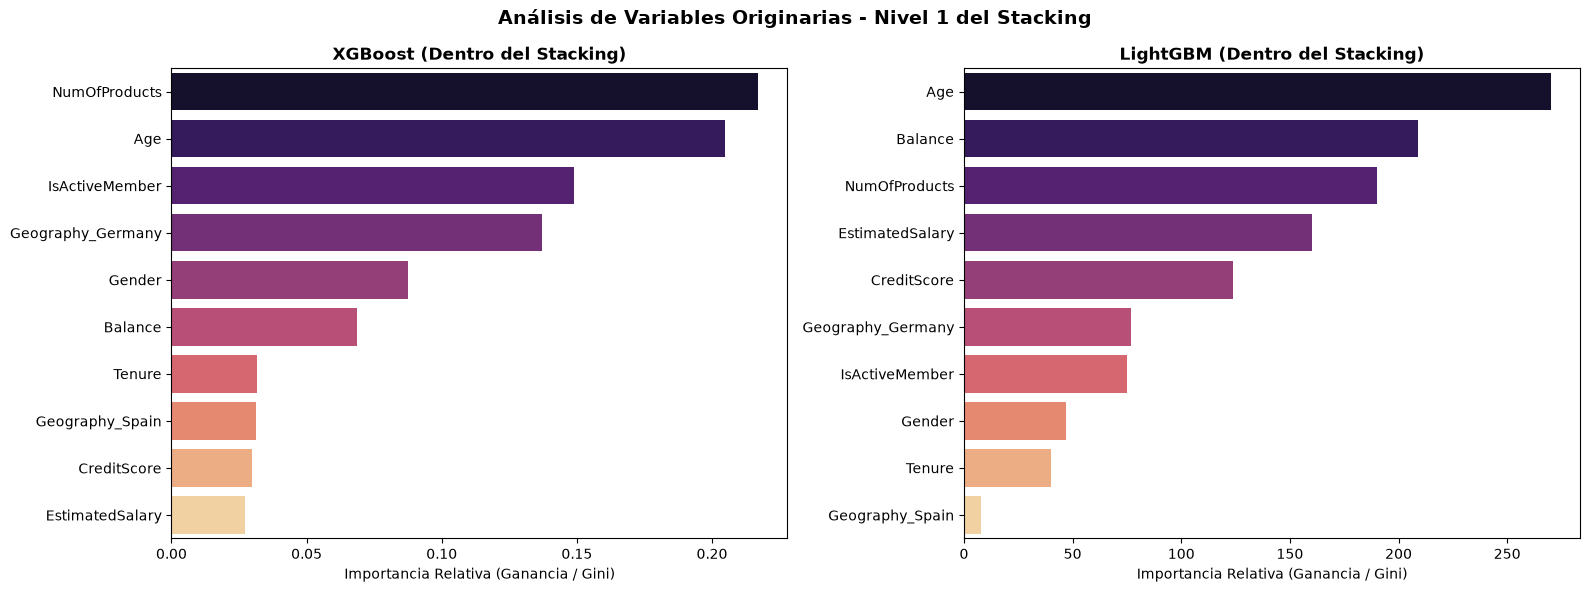

In [9]:
meta_lr = stacking.final_estimator_
meta_coefs = meta_lr.coef_[0] 

print(f'Meta-Learner (LogisticRegression) - Coeficientes de Decisión:')
print(f'Intercepto Base: {meta_lr.intercept_[0]:.4f}')

model_names_stack = ['xgb', 'lgbm', 'cat']
for i, name in enumerate(model_names_stack):
    if i < len(meta_coefs):
        print(f"Modelo [{name.upper()}] - Coeficiente asignado: {meta_coefs[i]:+.4f}")

print('-' * 60)

# Extraer los modelos entrenados desde el interior del Stacking
xgb_in_stack = stacking.named_estimators_['xgb']
lgb_in_stack = stacking.named_estimators_['lgbm']

columnas_banco = [
    'CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 
    'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
    'Geography_Germany', 'Geography_Spain'
]


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, estimator) in zip(axes, [('XGBoost (Dentro del Stacking)', xgb_in_stack),
                                        ('LightGBM (Dentro del Stacking)', lgb_in_stack)]):
    
    # DataFrame con las importancias del modelo escalado
    feat_df = pd.DataFrame({
        'Variable': columnas_banco,
        'Importancia': estimator.feature_importances_
    }).sort_values('Importancia', ascending=False)
    
    sns.barplot(data=feat_df.head(10), x='Importancia', y='Variable', ax=ax, palette='magma')
    ax.set_title(name, fontweight='bold', fontsize=12)
    ax.set_xlabel('Importancia Relativa (Ganancia / Gini)')
    ax.set_ylabel('')

plt.suptitle('Análisis de Variables Originarias - Nivel 1 del Stacking', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Nota: Para este análisis visual, se seleccionaron exclusivamente los modelos de XGBoost y LightGBM por representar formas de crecimiento de árboles más contrastantes dentro del ensamble (crecimiento por niveles vs. crecimiento por hojas asimétricas). Se omitió la importancia de variables de Random Forest por actuar únicamente como modelo base de control externo (Bagging), y la de CatBoost debido a la redundancia analítica que presenta en sus vectores de ganancia al procesar matrices numéricas previamente escaladas. Esto permite enfocar la interpretación del negocio en los dos motores predictivos que dominan las decisiones del Meta-Learner.

Comparativa de modelos

In [10]:
results = []
models = {
    'Random Forest': (y_pred_rf, y_pred_prob_rf),
    'XGBoost (Grid)': (y_pred_xgb, y_pred_prob_xgb),
    'LightGBM': (y_pred_lgbm, y_pred_prob_lgbm),
    'CatBoost': (y_pred_cat, y_pred_prob_cat),
    'Stacking': (y_pred_stacking, y_pred_prob_stacking)
}

for name, (y_pred, y_proba) in models.items():
    # Métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_proba)
    
    # PR-AUC
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = auc(recall_curve, precision_curve)
    
    results.append({
        'Modelo': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'ROC-AUC': roc,
        'PR-AUC': pr_auc
    })
    

df_results = pd.DataFrame(results).round(4).sort_values('Recall', ascending=False)

print("RANKING DE MODELOS (por Recall)")
print("=" * 85)
display(df_results)

# Mejor modelo
best = df_results.iloc[0]
print(f" MEJOR MODELO: {best['Modelo']}")
print(f"    ROC-AUC: {best['ROC-AUC']:.4f} | PR-AUC: {best['PR-AUC']:.4f} | F1: {best['F1']:.4f}")



RANKING DE MODELOS (por Recall)


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
4,Stacking,0.7960,0.4992,0.7838,0.6099,0.8728,0.7247
2,LightGBM,0.7965,0.5000,0.7690,0.6060,0.8729,0.7217
0,Random Forest,0.7930,0.4944,0.7568,0.5981,0.8561,0.6814
1,XGBoost (Grid),0.8060,0.5159,0.7568,0.6135,0.8692,0.7187
3,CatBoost,0.8085,0.5203,0.7568,0.6166,0.8714,0.7255


 MEJOR MODELO: Stacking
    ROC-AUC: 0.8728 | PR-AUC: 0.7247 | F1: 0.6099


Después de probar y ajustar todos los modelos avanzados, y tener un valor de ROC-AUC tan similar, se decide escoger por nuestra métrica de interes que es el Recall.
En base a esto, el Ensamble por Stacking es, el ganador y el modelo que el banco debería usar.
Aunque en la capacidad teórica para ordenar a los clientes por riesgo (ROC-AUC) quedó prácticamente empatado con LightGBM (ambos con 0.872), el Stacking lo supero ligeramente por un 1.48% en la medida del Recall. Para un umbral de decisión de 0.5, logró el Recall más alto de todo el proyecto (78.38%). Esto significa que atrapa a 78 de cada 100 clientes que realmente se van a ir del banco, lo que frena esa pérdida millonaria de dinero que descubrimos en el Avance 1(91,108.54 Euros en promedio por cliente). Además, un aspecto positivo es que la precision al ser de 49.92% la mitad de las alertas por posible desertor serán reales, a lo que el banco le puede dar manejo. 
La diferencia entre usar el primer o segundo modelo para el negocio sería en esa diferencia del 1.48% en recall, que equivaldría a 30 clientes (total de desertores 2037). En terminos financieros, la identificación de 2,746,703.82 de Euros al año.